# Assignment 3 - Transformer for IMDb Sentiment Classification

**Student:** Wimukthi Rajapaksha (a1988198)

A simplified encoder-only Transformer implemented from scratch in PyTorch (no `nn.Transformer`, `nn.MultiheadAttention` or Hugging Face model classes) for binary sentiment classification on IMDb.

**Pipeline:** Input -> Embedding -> Positional Encoding -> N x [Multi-Head Self-Attention -> Feed-Forward] -> masked mean pooling -> Classification head (softmax) -> Output


| Section | Contents|
|---|---|
| 0 | Setup and Configuration|
| 1 | Data Loading, Tokenisation, Vocabulary, Encoding, 80/20 split|
| 2 | Model Components (positional encoding, attention, multi-head attention, FFN, encoder block, classifier) |
| 3 | Training, evaluation, model selection, plotting, experiment runner|
| 4 | Experiments: Baseline (assignment configuration), then training-efficiency and performance experiments |
| 5 | Results, Analysis and Answers to the questions |

## 0. Setup

Recommended runtime: a GPU. The notebook picks the device automatically: an NVIDIA GPU (CUDA, e.g. Google Colab -> Runtime -> Change runtime type -> T4 GPU), otherwise an Apple-silicon GPU (MPS), otherwise the CPU (much slower). Mixed precision (`amp=True`) is used on CUDA only: in PyTorch 2.5, MPS autocast supports only bfloat16 and the fp16 gradient scaler fails on MPS, so the mixed-precision experiment is skipped on MPS and CPU. Some MPS kernels are not bitwise deterministic, so results there can vary slightly between runs.

**Note on `torchtext`:** the brief asks for preprocessing with `torchtext`. `torchtext` is deprecated, and its final release (0.18) works only with PyTorch 2.3 and NumPy 1.x, so the first code cell installs `torch==2.3.0`, `torchtext==0.18.0` and `numpy<2` and then restarts the session. **First run:** run the install cell, wait for the session to restart, then use *Run all*. On later runs the packages are already installed and the cell does nothing. The imports cell prints the versions and the tokenizer backend; it should read `torchtext basic_english`. torchtext 0.18 has no packages for Python 3.13 or later; if it cannot be installed, the notebook falls back to an exact re-implementation whose twelve regular-expression rules are copied verbatim from torchtext's source (`torchtext/data/utils.py`, function `_basic_english_normalize`), so tokenisation is identical in both cases.

In the submitted run, Colab's runtime used Python 3.13, so the install failed (see the output of the install cell) and the re-implementation was used.

In [3]:
# Install the versions torchtext needs (see the note above): torchtext 0.18 works only with PyTorch 2.3 and NumPy 1.x.
# First run: this cell installs them and then restarts the session (the kernel stops on purpose).
# After the restart, use Run all; torchtext is then found and the install is skipped.
import importlib.util, os

def _installed_version(package):
    """Version string of an installed package, or None if it is not installed."""
    from importlib.metadata import version, PackageNotFoundError
    try:
        return version(package)
    except PackageNotFoundError:
        return None

_needs_install = (importlib.util.find_spec("torchtext") is None
                  or not (_installed_version("torch") or "").startswith("2.3.0")
                  or (_installed_version("numpy") or "2").split(".")[0] != "1")
if _needs_install:
    import subprocess, sys
    _result = subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                              "torch==2.3.0", "torchtext==0.18.0", "numpy<2"])
    if _result.returncode == 0:
        print("Installed torch 2.3.0, torchtext 0.18.0 and numpy<2. Restarting the session; then use Run all.")
        os.kill(os.getpid(), 9)    # restart so the new versions are loaded
    else:
        print(f"torchtext could not be installed (it needs Python 3.12 or older; this is Python "
              f"{sys.version.split()[0]}). The notebook will use the exact re-implementation of its tokenizer.")
else:
    print("torch", _installed_version("torch"), "| torchtext", _installed_version("torchtext"),
          "| numpy", _installed_version("numpy"), "- already installed")
# !pip install -q datasets matplotlib scikit-learn pandas  # uncomment if another package is missing


torchtext could not be installed (it needs Python 3.12 or older; this is Python 3.13.16). The notebook will use the exact re-implementation of its tokenizer.


In [4]:
# pip install -U ipywidgets jupyterlab_widgets

In [5]:
import os, re, math, time, random
from contextlib import nullcontext
from functools import partial
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Sampler
from datasets import load_dataset

# torchtext is optional (see note above); fall back to an identical re-implementation
try:
    import torchtext
    from torchtext.data.utils import get_tokenizer
    _TT_TOKENIZER = get_tokenizer("basic_english")
    TOKENIZER_BACKEND = f"torchtext basic_english (torchtext {torchtext.__version__})"
except Exception as exc: # ImportError / OSError on incompatible torch builds
    _TT_TOKENIZER = None
    TOKENIZER_BACKEND = f"basic_english re-implementation (torchtext unavailable: {type(exc).__name__})"

print("PyTorch:", torch.__version__, "| NumPy:", np.__version__)
print("Tokenizer backend:", TOKENIZER_BACKEND)

PyTorch: 2.11.0+cu130 | NumPy: 2.1.3
Tokenizer backend: basic_english re-implementation (torchtext unavailable: ModuleNotFoundError)


## Configuration

The first three lines are the assignment's required hyperparameters (batch size 32, learning rate 0.001, 10 epochs, Adam). The remaining keys control the model options described in Section 2 and the additions used in Section 4's experiments; their defaults reproduce the assignment configuration exactly.

In [6]:
CFG = dict(
    seed=42,
    max_len=256,
    min_freq=2,
    max_vocab=20000,
    d_model=128,
    n_heads=4,
    d_ff=256,
    n_layers=2,
    dropout=0.1,
    # --- model options (defaults = the model described in Section 2) ---

    num_classes=2,       # output logits; evaluate() reports binary metrics, so it expects 2
    pooling="mean",      # "mean": masked mean over real tokens; "cls": a learned [CLS] vector at position 0
    norm_first=False,    # False: Post-LN blocks (original Transformer); True: Pre-LN blocks
    activation="relu",   # feed-forward activation: "relu" (assignment) or "gelu"
    pe_base=10000.0,     # base of the sinusoidal positional-encoding frequencies
    batch_size=32,
    lr=1e-3,
    epochs=10,

    # --- additions (defaults = assignment configuration) ---
    eval_batch_size=256,    # larger batches for validation/ test only (no effect on training)
    grad_clip=1.0,          # max gradient L2-norm; stabilises training at lr = 1e-3
    select_by="val_loss",   # model-selection criterion for the saved checkpoint
    use_padding_mask=True,  # mask <pad> tokens in attention and pooling
    truncation="head",      # "head": keep the first max_len tokens; "head_tail": keep the start and the end
    dynamic_padding=False,  # pad each batch to its own longest review (+ length bucketing)
    pad_multiple=16,        # with dynamic padding, round each batch length up to a multiple of this
    amp=False,              # automatic mixed precision (CUDA only)
    weight_decay=0.0,       # > 0 replaces Adam with AdamW (decoupled weight decay)
    lr_schedule="constant",  # "constant", or "warmup_cosine": linear warm-up to lr, then cosine decay to 0
    warmup_frac=0.1         # share of all training steps used for warm-up
)

PAD_TOKEN, UNK_TOKEN = "<pad>", "<unk>"
PAD_IDX, UNK_IDX = 0, 1

def get_device() -> torch.device:
    """Pick the fastest available backend: NVIDIA GPU (CUDA), then Apple-silicon GPU (MPS), then CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def sync_device() -> None:
    '''Block until all queued GPU work has finished, so wall-clock timings are accurate.

    GPU kernels run asynchronously; without this, timing a CUDA/MPS epoch would only measure
    how long it took to queue the work. No-op on CPU.
    '''

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "mps":
        torch.mps.synchronize()

def allocated_memory_mb() -> float:
    '''Memory currently allocated to tensors on the GPU (CUDA or MPS), in MB; NaN on CPU.

    Unlike the driver's total, this excludes PyTorch's cache of freed blocks and compiled kernels,
    so it does not depend on what earlier runs in the same process did.
    '''

    if DEVICE.type == "cuda":
        return torch.cuda.memory_allocated() / 2**20
    if DEVICE.type == "mps":
        return torch.mps.current_allocated_memory() / 2**20
    return float("nan")


DEVICE = get_device()
FIG_DIR, CKPT_DIR = "figures", "checkpoints"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)


print("Device:", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE.type=="cuda" else "")

def set_seed(seed: int) -> None:
    '''Seed Python, NumPy and PyTorch (CPU and CUDA) for reproducibility.'''
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False


Device: cuda (Tesla T4)


## 1. Data loading and Preprocessing

Steps:
1. **Load** IMDb from Hugging Face `datasets` (25,000 train / 25,000 test, balanced).
2. **Split** The official training set 80/20 into train (20,000) and validation (5,000) after a seeded shuffle. The official test set is never used for any training or model-selection decision.
3. **Tokenise** Strip HTML tags (IMDb reviews contain `<br />`), lowercase, and split words and punctuation with the `basic_english` rules.
4. **Vocabulary** Built from the training split only (to avoid leakage): tokens with frequency >= 2, capped at the 20,000 most frequent; index 0 = `<pad>`, 1 = `<unk>`.
5. **Encode**: Map tokens to ids (unknown -> `<unk>`), truncate to `max_len` (keeping the beginning; §4.4 also tests keeping the beginning and the end), right-pad with `<pad>` to a uniform length.

In [7]:
_HTML_TAG_RE = re.compile(r"<[^>]+>")

# Exact copy of torchtext's basic_english normalisation rules (used if torchtext is unavailable).

_BASIC_ENGLISH_RULES = [
    (re.compile(r"\'"), " '  "),
    (re.compile(r"\""), ""),
    (re.compile(r"\."), " . "),
    (re.compile(r"<br \/>"), " "),
    (re.compile(r","), " , "),
    (re.compile(r"\("), " ( "),
    (re.compile(r"\)"), " ) "),
    (re.compile(r"\!"), " ! "),
    (re.compile(r"\?"), " ? "),
    (re.compile(r"\;"), " "),
    (re.compile(r"\:"), " "),
    (re.compile(r"\s+"), " "),
]

def _basic_english(text: str) -> list[str]:
    """Lowercase and apply the basic_english rules: split off . , ( ) ! ? as separate tokens,
    put apostrophes in their own token, drop double quotes, semicolons and colons, then split on whitespace."""
    text = text.lower()
    for pattern, repl in _BASIC_ENGLISH_RULES:
        text = pattern.sub(repl, text)
    return text.split()

def tokenize(text: str) -> list[str]:
    """Lowercase, strip HTML tags such as <br />, and split into word/punctuation tokens."""
    text = _HTML_TAG_RE.sub(" ", text)
    if _TT_TOKENIZER is not None:
        return _TT_TOKENIZER(text)
    return _basic_english(text)


print(tokenize("This movie was GREAT!<br /><br />I didn't expect (much), honestly..."))

['this', 'movie', 'was', 'great', '!', 'i', 'didn', "'", 't', 'expect', '(', 'much', ')', ',', 'honestly', '.', '.', '.']


In [8]:
def build_vocab(texts, min_freq, max_vocab) -> dict[str, int]:
    '''Count tokens over the TRAINING split only and map each kept token to an index.

    Index 0 = <pad>, 1 = <unk>. Tokens are kept in descending frequency order while
    frequency >= min_freq and the vocabulary (including specials) has < max_vocab entries.
    '''

    counter = Counter()
    for text in texts:
        counter.update(tokenize(text))

    vocab = {PAD_TOKEN: PAD_IDX, UNK_TOKEN: UNK_IDX}
    for token, freq in counter.most_common():
        if freq<min_freq or len(vocab)>=max_vocab:
            break
        vocab[token]=len(vocab)
    return vocab


In [9]:
def encode(text, vocab, max_len, truncation="head") -> tuple[list[int], int]:
    '''Tokens -> ids (unknown -> <unk>), truncate to max_len, right-pad with <pad>.

    truncation="head" keeps the first max_len tokens. "head_tail" keeps the first quarter of
    max_len and fills the rest from the end of the review, where reviewers often state their
    verdict; the input size (and so the training cost) is the same as for "head".
    Returns (ids, true_length), where true_length is the number of non-pad tokens.
    '''

    ids = [vocab.get(tok, UNK_IDX) for tok in tokenize(text)]
    if len(ids)>max_len:
        if truncation == "head_tail":
            head = max_len//4
            ids=ids[:head] + ids[-(max_len-head):]
        else:
            ids = ids[:max_len]
    if not ids:  # guard: an empty review still gets one real token
        ids = [UNK_IDX]
    true_length = len(ids)
    ids = ids + [PAD_IDX]*(max_len - true_length)
    return ids, true_length

In [10]:
class IMDbDataset(Dataset):
    '''Pre-encodes every review once; __getitem__ returns (ids, true_length, label) tensors.'''

    def __init__(self, texts, labels, vocab, max_len, truncation="head"):
        encoded = [encode(t, vocab, max_len, truncation) for t in texts]
        self.ids = torch.tensor([e[0] for e in encoded], dtype=torch.long)       # (N, max_len)
        self.lengths = torch.tensor([e[1] for e in encoded], dtype=torch.long)   # (N,)
        self.labels = torch.tensor(list(labels), dtype=torch.long)               # (N,)
        self.max_len = max_len

    def __len__(self):
        """Number of reviews."""
        return len(self.labels)

    def __getitem__(self, idx):
        """Review idx as (token ids (max_len,), true length, label)."""
        return self.ids[idx], self.lengths[idx], self.labels[idx]

In [11]:
def load_and_split(seed, val_fraction=0.2):
    """Load IMDb from Hugging Face, shuffle the official train split with a fixed seed and
    split it 80/20 into train/validation. The official test split is returned untouched.

    Returns ((train_texts, train_labels), (val_texts, val_labels), (test_texts, test_labels)).
    """

    ds = load_dataset("stanfordnlp/imdb")
    full_train = ds["train"].shuffle(seed=seed)
    n_val = int(len(full_train)*val_fraction)
    val_split = full_train.select(range(n_val))
    train_split = full_train.select(range(n_val, len(full_train)))

    def unpack(split):
        """Hugging Face split -> (list of review texts, list of labels)."""
        return list(split["text"]), list(split["label"])
    return unpack(train_split), unpack(val_split), unpack(ds["test"])

### Batching utilities (used by the efficiency experiments)

With fixed padding every batch has shape (32, 256), regardless of how long its reviews are. **Dynamic padding** trims each batch to its own longest review; **length bucketing** groups reviews of similar length into the same batch so that little padding remains. Batches are still shuffled each epoch, so training remains stochastic. Each batch length is rounded up to a multiple of `pad_multiple` (16): the MPS backend compiles a new kernel graph for every new tensor shape, so unrounded lengths (up to `max_len` different shapes) made the first epoch slow in an earlier MPS run; on CUDA, §4.4.1 shows no such cost and rounding costs only 2–3%. CUDA tensor cores also work best with multiples of 8. Validation and test batches keep the dataset order so that predictions line up with the review texts.

In [12]:
def collate_dynamic(batch, pad_multiple=1):
    '''Stack a batch and trim the padded ids to the longest review in the batch, rounded up to a multiple of pad_multiple (which keeps the number of distinct batch shapes small).'''
    ids, lengths, labels = zip(*batch)
    ids, lengths, labels = torch.stack(ids), torch.stack(lengths), torch.stack(labels)
    seq_len = min(ids.size(1), math.ceil(int(lengths.max()) / pad_multiple) * pad_multiple)
    return ids[:, :seq_len], lengths, labels

class BucketBatchSampler(Sampler):
    """Yields batches of indices whose reviews have similar lengths.

    Each epoch: shuffle all indices, cut them into chunks of batch_size * bucket_mult,
    sort each chunk by length, slice it into batches, then shuffle the batch order.
    """

    def __init__(self, lengths, batch_size, shuffle=True, bucket_mult=50, seed=0):
        self.lengths=list(lengths)
        self.batch_size, self.shuffle = batch_size, shuffle
        self.chunk = batch_size * bucket_mult
        self.seed, self.epoch = seed, 0

    def __iter__(self):
        """Yield one epoch of batches (lists of dataset indices); a new shuffle every epoch."""
        g = torch.Generator()
        g.manual_seed(self.seed+self.epoch)
        self.epoch += 1
        n = len(self.lengths)
        order = torch.randperm(n, generator=g).tolist() if self.shuffle else list(range(n))
        batches = []
        for start in range(0, n, self.chunk):
            chunk = sorted(order[start:start+self.chunk], key=lambda i: self.lengths[i])
            batches += [chunk[k:k+self.batch_size] for k in range(0, len(chunk), self.batch_size)]
        if self.shuffle:
            batches = [batches[i] for i in torch.randperm(len(batches), generator=g).tolist()]
        return iter(batches)

    def __len__(self):
        """Number of batches per epoch."""
        return math.ceil(len(self.lengths) / self.batch_size)


def make_loaders(datasets_, cfg):
    """Build train/val/test DataLoaders for the given (train, val, test) datasets and config.

    With dynamic padding, training batches come from the length-bucketing sampler; validation and
    test batches keep the dataset order (only their padding is trimmed), so the predictions line
    up with the review texts for error analysis."""

    train_ds, val_ds, test_ds = datasets_
    common = dict(num_workers = 0, pin_memory=(DEVICE.type=="cuda"))

    if cfg["dynamic_padding"]:
        collate = partial(collate_dynamic, pad_multiple=cfg["pad_multiple"])
        sampler = BucketBatchSampler(train_ds.lengths.tolist(), cfg["batch_size"], seed=cfg["seed"])
        train_loader = DataLoader(train_ds, batch_sampler=sampler, collate_fn=collate, **common)
    else:
        collate = None    # default collate; fixed max_len batches
        g = torch.Generator()
        g.manual_seed(cfg["seed"])
        train_loader = DataLoader(train_ds, batch_size=cfg["batch_size"], shuffle=True, generator=g, **common)

    def eval_loader(ds):
        """Unshuffled loader in dataset order (validation/test)."""
        return DataLoader(ds, batch_size=cfg["eval_batch_size"], shuffle=False, collate_fn=collate, **common)

    return train_loader, eval_loader(val_ds), eval_loader(test_ds)

## 2. Model Components

All components below are written from scratch with basic tensor operations and `nn.Linear` / `nn.Embedding` / `nn.LayerNorm`. No built-in attention or Transformer modules are used. Settings that the assignment fixes are configurable rather than hard-coded (see `CFG`): the number of output classes, the pooling (masked mean or a learned `[CLS]` vector), Post-LN or Pre-LN blocks, the feed-forward activation and the positional-encoding base. The defaults give the model used in all experiments.

In [13]:
class PositionalEncoding(nn.Module):
    """Sinusoidal positional encoding (Vaswani et al., 2017):
        PE[pos, 2i]       = sin(pos / base^(2i/d_model))
        PE[pos, 2i+1]     = cos(pos / base^(2i/d_model))
    with base = 10000 by default. Stored as a non-trainable buffer. Forward: x (B, L, d_model) -> (B, L, d_model)
    """

    def __init__(self, d_model, max_len, base=10000.0):
        super().__init__()
        position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)      # (max_len, 1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32)
                                * (-math.log(base) / d_model))                  # (d_model/2,)
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0), persistent=False)           # (1, max_len, d_model)

    def forward(self, x):
        """Add the encodings of positions 0 .. L-1 to x."""
        return x + self.pe[:, : x.size(1)]

In [14]:
def scaled_dot_product_attention(q, k, v, mask=None, dropout=None):
    """Attention(Q, K, V) = softmax(Q K^T / sqrt(d_k)) V

    q, k, v : (B, H, L, d_k)
    mask    : bool, broadcastable to (B, H, L, L); True where attention is NOT allowed (padding)
    dropout : optional nn.Dropout applied to the attention weights
    Returns (output (B, H, L, d_k), attention weights (B, H, L, L)).
    """
    d_k = q.size(-1)
    scores = torch.matmul(q, k.transpose(-2, -1))/math.sqrt(d_k)  # (B, H, L, L)
    if mask is not None:
        # Mask BEFORE softmax: padded keys receive ~zero weight. finfo.min (rather than -inf)
        # stays finite under fp16 mixed precision.
        scores = scores.masked_fill(mask, torch.finfo(scores.dtype).min)
    attn = torch.softmax(scores, dim=-1)
    out = torch.matmul(dropout(attn) if dropout is not None else attn, v)
    return out, attn

In [15]:
class MultiHeadAttention(nn.Module):
    '''Multi-head self-attention.

    W_q, W_k, W_v project x into queries/keys/values; these are split into n_heads heads of
    size d_k = d_model / n_heads, each head attends independently, the heads are concatenated
    and W_o mixes them. forward: x (B, L, d_model), mask -> (B, L, d_model)
    '''

    def __init__(self, d_model, n_heads, dropout):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.n_heads, self.d_k = n_heads, d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.attn_dropout = nn.Dropout(dropout)
        self.store_attn, self.last_attn = False, None  # for attention visualisation only

    def _split_heads(self, x):
        """(B, L, d_model) -> (B, H, L, d_k): give each head its own slice of the features"""

        B, L, _ = x.shape
        return x.view(B, L, self.n_heads, self.d_k).transpose(1,2)

    def _merge_heads(self, x):
        """(B, H, L, d_k) -> (B, L, d_model): concatenate the heads' outputs."""
        B, H, L, d_k = x.shape
        return x.transpose(1, 2).contiguous().view(B, L, H*d_k)

    def forward(self, x, mask=None):
        """Project x to Q, K, V, attend in every head (optionally masking keys), merge the heads and apply W_o."""
        q = self._split_heads(self.W_q(x))
        k = self._split_heads(self.W_k(x))
        v = self._split_heads(self.W_v(x))
        out, attn = scaled_dot_product_attention(q, k, v, mask, self.attn_dropout)
        if self.store_attn:
            self.last_attn = attn.detach()
        return self.W_o(self._merge_heads(out))

In [16]:
ACTIVATIONS = {"relu": nn.ReLU, "gelu": nn.GELU}

class FeedForward(nn.Module):
    """Position-wise two-layer FFN: Linear(d_model, d_ff) -> activation -> Dropout -> Linear(d_ff, d_model).
    The activation is ReLU by default (as the assignment requires); "gelu" is also available"""

    def __init__(self, d_model, d_ff, dropout, activation="relu"):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            ACTIVATIONS[activation](),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
        )
    def forward(self, x):
        """Apply the same two-layer network to every position independently: (B, L, d_model) -> (B, L, d_model)"""
        return self.net(x)

In [17]:
class EncoderBlock(nn.Module):
    """Encoder block: multi-head self-attention and a feed-forward network, each with a residual
    connection, dropout and LayerNorm.

    Post-LN (norm_first=False, original Transformer; used in all experiments):
        x = LayerNorm(x + Dropout(MultiHeadAttention(x)))
        x = LayerNorm(x + Dropout(FeedForward(x)))
    Pre-LN (norm_first=True; trains more stably without learning-rate warm-up):
        x = x + Dropout(MultiHeadAttention(LayerNorm(x)))
        x = x + Dropout(FeedForward(LayerNorm(x)))
    """

    def __init__(self, d_model, n_heads, d_ff, dropout, norm_first=False, activation="relu"):
        super().__init__()
        self.norm_first = norm_first
        self.attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ffn = FeedForward(d_model, d_ff, dropout, activation)
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop1, self.drop2 = nn.Dropout(dropout), nn.Dropout(dropout)

    def forward(self, x, mask=None):
        """(B, L, d_model) -> (B, L, d_model); mask marks padded keys (True = do not attend)"""
        if self.norm_first:
            x = x + self.drop1(self.attn(self.norm1(x), mask))
            x = x + self.drop2(self.ffn(self.norm2(x)))
        else:
            x = self.norm1(x + self.drop1(self.attn(x, mask)))
            x = self.norm2(x + self.drop2(self.ffn(x)))
        return x

In [18]:
class TransformerClassifier(nn.Module):
    """Input -> Embedding -> PosEnc -> N x EncoderBlock -> pooling -> head

    Output: num_classes logits (2 by default: negative, positive). Softmax over the logits gives the
    class probabilities, and nn.CrossEntropyLoss on 2 classes is exactly the binary cross-entropy
    -[y log p + (1 - y) log(1 - p)] with p = softmax(logits)[1]. This satisfies both the
    "softmax output" and "binary cross-entropy" requirements, and CrossEntropyLoss computes it
    from log-softmax, which is numerically stable.

    Pooling: "mean" averages the encoder outputs of the real tokens; "cls" prepends a learned [CLS]
    vector at position 0 and classifies from its output. Pre-LN models get a final LayerNorm.
    forward: ids (B, L) -> logits (B, num_classes)
    """

    def __init__(self, vocab_size, cfg):
        super().__init__()
        d_model = cfg["d_model"]
        self.use_padding_mask = cfg.get("use_padding_mask", True)
        self.pooling = cfg.get("pooling", "mean")
        assert self.pooling in ("mean", "cls"), f"unknown pooling {self.pooling!r}"
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_IDX)

        # Small init then scale by sqrt(d_model): embeddings start at unit scale, comparable
        # to the positional encoding, so position information is not drowned out.

        nn.init.normal_(self.embedding.weight, mean=0.0, std=d_model ** -0.5)
        with torch.no_grad():
            self.embedding.weight[PAD_IDX].zero_()
        self.emb_scale = math.sqrt(d_model)
        n_positions = cfg["max_len"] + (1 if self.pooling == "cls" else 0)
        self.pos_enc = PositionalEncoding(d_model, n_positions, cfg.get("pe_base", 10000.0))
        self.emb_dropout = nn.Dropout(cfg["dropout"])
        self.layers = nn.ModuleList([
            EncoderBlock(d_model, cfg["n_heads"], cfg["d_ff"], cfg["dropout"],
                            cfg.get("norm_first", False), cfg.get("activation", "relu"))
            for _ in range(cfg["n_layers"])
        ])

        # Pre-LN leaves the residual stream unnormalised, so it needs a final LayerNorm.
        self.final_norm = nn.LayerNorm(d_model) if cfg.get("norm_first", False) else nn.Identity()
        self.head = nn.Sequential(nn.Dropout(cfg["dropout"]), nn.Linear(d_model, cfg.get("num_classes",2)))
        if self.pooling == "cls":
            self.cls = nn.Parameter(torch.zeros(1, 1, d_model))
            nn.init.normal_(self.cls, std=d_model ** -0.5)

    def make_padding_mask(self, ids):
        """(B, L) ids -> (B, 1, 1, L) bool mask, True at <pad> keys; broadcasts over heads and queries."""
        return (ids == PAD_IDX)[:, None, None, :]

    def pool(self, x, ids):
        """Masked mean pooling: average the encoder outputs of real (non-pad) tokens only"""
        keep = (ids != PAD_IDX).unsqueeze(-1).type_as(x)                # (B, L, 1)
        return (x * keep).sum(dim=1) / keep.sum(dim=1).clamp(min=1.0)   # (B, d_model)

    def forward(self, ids):
        """Token ids (B, L) -> class logits (B, num_classes)"""
        mask = self.make_padding_mask(ids) if self.use_padding_mask else None
        x = self.embedding(ids) * self.emb_scale        # (B, L, d_model)
        if self.pooling == "cls":                        # [CLS] at position 0, never masked
            x = torch.cat([self.cls.expand(x.size(0), -1, -1), x], dim=1)
            if mask is not None:
                mask = torch.cat([torch.zeros_like(mask[..., :1]), mask], dim=-1)
        x = self.emb_dropout(self.pos_enc(x))
        for layer in self.layers:
            x = layer(x, mask)
        x = self.final_norm(x)
        if self.pooling == "cls":
            pooled = x[:, 0]
        else:
            pooled = self.pool(x, ids) if self.use_padding_mask else x.mean(dim=1)
        return self.head(pooled)   # (B, num_classes)

def count_parameters(model):
    """Number of trainable parameters"""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

### Unit Checks

Quick shape and masking checks on random inputs before training, for the default model and for the alternative options ([CLS] pooling, Pre-LN, GELU, 3 classes).

In [19]:
_cfg = {**CFG, "max_len": 16}
_m = TransformerClassifier(vocab_size=50, cfg=_cfg).eval()
_ids = torch.randint(2, 50, (3, 16))
_ids[0, 10:] = PAD_IDX                  # first sequence has 6 pad tokens

assert _m(_ids).shape == (3, 2)

# Padding mask: pad keys must get ~zero attention weight
_q = torch.randn(3, 4, 16, 8)
_, _w = scaled_dot_product_attention(_q, _q, _q, _m.make_padding_mask(_ids))
assert _w.shape == (3, 4, 16, 16) and _w[0, :, :, 10:].max() < 1e-6
assert torch.allclose(_w.sum(-1), torch.ones(3, 4, 16))

# Extra padding must not change the prediction: same review with 0 vs 6 pad tokens
with torch.no_grad():
    _a = _m(_ids[:1, :10])[0]
    _b = _m(_ids[:1])[0]

assert torch.allclose(_a, _b, atol=1e-5)

# The configurable options: output shape and padding invariance must hold for every variant
_alt = TransformerClassifier(vocab_size=50, cfg={**_cfg,
                                                 "pooling": "cls",
                                                 "norm_first": True,
                                                 "activation": "gelu",
                                                 "num_classes": 3
                                                }).eval()
assert _alt(_ids).shape == (3,3)
with torch.no_grad():
    assert torch.allclose(_alt(_ids[:1, :10])[0], _alt(_ids[:1])[0], atol=1e-5)

print("All unit checks passed.")

All unit checks passed.


## 3. Training and Evaluation

* **Optimiser:** Adam, lr = 0.001; mini-batches of 32; 10 epochs.
* **Loss:** `nn.CrossEntropyLoss` over two softmax classes (= binary cross-entropy; see the classifier docstring).
* **Gradient clipping** (max-norm 1.0): Post-LN Transformers trained without learning-rate warmup at lr = 1e-3 can have occasional gradient spikes; clipping bounds the update size.
* **Experiment-only options** (off by default, used in §4.4): AdamW weight decay (biases and LayerNorm parameters excluded) and a learning-rate schedule with linear warm-up to the assignment's 0.001 followed by cosine decay.
* **Model selection:** after every epoch the model is evaluated on the validation set, and the checkpoint with the lowest **validation loss** is saved. That checkpoint, not the last epoch, is evaluated on the test set. Validation loss is used rather than accuracy because it also penalises over-confident wrong predictions, so it detects the onset of overfitting earlier.

In [20]:
def _to_device(ids, labels):
    """
    Move a batch of token ids and labels to DEVICE.

    Asynchronous (non_blocking) copies are only safe from pinned memory, which the loaders use
    on CUDA only. On MPS a non-blocking copy from ordinary memory can read the CPU tensor after
    it has been freed, silently corrupting the labels, so MPS and CPU copy synchronously.
    """

    non_blocking = DEVICE.type == "cuda"
    return ids.to(DEVICE, non_blocking=non_blocking), labels.to(DEVICE, non_blocking=non_blocking)

def train_one_epoch(model, loader, optimizer, criterion, grad_clip=None, scaler=None, scheduler=None) -> dict:
    """
    One pass over the training data: forward, loss, backward, gradient clipping, Adam step
    (plus a per-step learning-rate update if a scheduler is given).

    If a GradScaler is given, the forward pass runs under fp16 autocast (mixed precision).
    Returns the average loss and accuracy over the epoch, the work done, which does not depend on
    the hardware (token positions processed, sum of B x L, and attention scores computed per head
    and layer, sum of B x L^2), and the peak memory allocated to tensors, sampled after each forward
    pass, when the activations kept for the backward pass are all allocated.
    """

    model.train()
    total_loss, correct, n = 0.0, 0, 0
    positions, attn_entries = 0, 0
    peak_mem = allocated_memory_mb()
    use_amp = scaler is not None

    for ids, _lengths, labels in loader:
        ids, labels = _to_device(ids, labels)
        optimizer.zero_grad(set_to_none=True)

        # Mixed precision is CUDA-only here; on MPS/CPU the forward pass runs in fp32
        with torch.autocast(device_type="cuda", dtype=torch.float16) if use_amp else nullcontext():
            logits = model(ids)
            loss = criterion(logits, labels)
        peak_mem = max(peak_mem, allocated_memory_mb())

        if use_amp:
            scaler.scale(loss).backward()
            if grad_clip:
                scaler.unscale_(optimizer)  # clip the true (unscaled) gradients
                nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            if grad_clip:
                nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()
        if scheduler is not None:
            scheduler.step()

        batch_size, seq_len = ids.shape
        total_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        n += batch_size
        positions += batch_size * seq_len
        attn_entries += batch_size * seq_len ** 2

    return dict(loss=total_loss / n, acc=correct / n, positions=positions, attn_entries=attn_entries, peak_mem_mb=peak_mem)

In [21]:
def binary_metrics(y_true, y_pred) -> dict:
    """Accuracy, precision, recall and F1 for the positive class (1), from the TP/FP/FN/TN counts"""
    tp = int(((y_pred==1)&(y_true==1)).sum())
    fp = int(((y_pred==1)&(y_true==0)).sum())
    fn = int(((y_pred==0)&(y_true==1)).sum())
    tn = int(((y_pred==0)&(y_true==0)).sum())

    precision = tp/(tp+fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return dict(accuracy=(tp+tn)/len(y_true), precision=precision, recall=recall, f1=f1, tp=tp, fp=fp, fn=fn, tn=tn)

def per_class_report(m) -> pd.DataFrame:
    """Precision, recall, F1 and support for each class, plus their macro average, from the
    TP/FP/FN/TN counts of binary_metrics(). For the negative class, TN plays the role of TP"""

    def prf(tp, fp, fn):
        '''Precision, recall and F1 of one class from its TP, FP, and FN counts (0 when undefined)'''
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp +fn) if tp + fn else 0.0
        return p, r, (2 * p * r / (p + r) if p + r else 0.0)

    report = pd.DataFrame({"negative (0)": (*prf(m["tn"], m["fn"], m["fp"]), m["tn"] + m["fp"]),
                          "positive (1)": (*prf(m["tp"], m["fp"], m["fn"]), m["tp"] + m["fn"])},
                        index=["precision", "recall", "f1", "support"]).T
    report.loc["macro average"] = [*report.iloc[:2, :3].mean(), report["support"].sum()]
    return report


@torch.no_grad()
def evaluate(model, loader, criterion, return_preds=False) -> dict:
    """
    Loss plus the binary metrics above (positive class = 1) over a whole loader.
    With return_preds, also the true labels, predicted labels and P(positive) for every review
    """

    model.eval()
    total_loss, n = 0.0, 0
    y_true, y_pred, p_pos = [], [], []

    for ids, _lengths, labels in loader:
        ids, labels = _to_device(ids, labels)
        logits = model(ids)
        total_loss += criterion(logits, labels).item() * labels.size(0)
        n += labels.size(0)
        y_true.append(labels.cpu())
        y_pred.append(logits.argmax(dim=1).cpu())
        p_pos.append(torch.softmax(logits.float(), dim=1)[:, 1].cpu())

    y_true = torch.cat(y_true).numpy()
    y_pred = torch.cat(y_pred).numpy()
    out = dict(loss=total_loss / n, **binary_metrics(y_true, y_pred))
    if return_preds:
        out.update(y_true=y_true, y_pred=y_pred, prob_pos=torch.cat(p_pos).numpy())
    return out

In [22]:
def make_optimizer(model, cfg):
    """
    Adam at cfg['lr'] (assignment configuration). If cfg['weight_decay'] > 0, AdamW is used instead:
    Adam with decoupled weight decay, applied to weight matrices and embeddings but not to biases
    or LayerNorm parameters (the 1-D tensors).
    """

    if not cfg["weight_decay"]:
        return torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    decay = [p for p in model.parameters() if p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.dim() < 2]
    return torch.optim.AdamW([{"params": decay, "weight_decay": cfg["weight_decay"]},
                              {"params": no_decay, "weight_decay": 0.0}], lr=cfg["lr"])

def make_scheduler(optimizer, cfg, steps_per_epoch):
    """
    None for a constant learning rate. For "warmup_cosine", a per-step schedule that rises
    linearly to cfg['lr'] over the first warmup_frac of all steps, then decays to 0 along a half cosine.
    """

    if cfg["lr_schedule"] == "constant":
        return None
    total = cfg["epochs"] * steps_per_epoch
    warmup = max(1, int(cfg["warmup_frac"] * total))

    def factor(step):
        """Multiplier of cfg['lr'] at a given optimiser step"""
        if step < warmup:
            return (step + 1) / warmup
        return 0.5 * (1.0 + math.cos(math.pi * (step - warmup) / max(1, total - warmup)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, factor)

def fit(model, train_loader, val_loader, cfg) -> dict:
    """
    Train for cfg['epochs'] epochs, log train/val metrics in a history dict and save the
    best checkpoint (by validation loss, or accuracy if cfg['select_by'] == 'val_acc')
    """

    optimizer = make_optimizer(model, cfg)
    scheduler = make_scheduler(optimizer, cfg, steps_per_epoch=len(train_loader))
    criterion = nn.CrossEntropyLoss()
    scaler = None
    if cfg["amp"] and DEVICE.type == "cuda":
        # torch.amp.GradScaler("cuda") is the current API; torch.cuda.amp.GradScaler works on older PyTorch
        scaler = (torch.amp.GradScaler("cuda") if hasattr(torch.amp, "GradScaler")
                  else torch.cuda.amp.GradScaler())

    by_loss = cfg["select_by"] == "val_loss"
    best_score = math.inf if by_loss else -math.inf
    history = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_f1", "epoch_time",
        "positions", "attn_entries", "mem_mb"]}

    # Memory already allocated (this model's weights, and any earlier models kept in the notebook);
    # training memory is reported above this level so that runs are comparable
    mem_before = allocated_memory_mb()

    for epoch in range(1, cfg["epochs"]+1):
        sync_device()
        t0 = time.perf_counter()
        train = train_one_epoch(model, train_loader, optimizer, criterion,
        grad_clip=cfg["grad_clip"], scaler=scaler, scheduler=scheduler)

        sync_device()
        epoch_time = time.perf_counter() - t0 # training time only (excludes validation)

        val = evaluate(model, val_loader, criterion)
        for key, value in [("train_loss", train["loss"]), ("train_acc", train["acc"]), ("val_loss", val["loss"]),
                           ("val_acc", val["accuracy"]), ("val_f1", val["f1"]), ("epoch_time", epoch_time),
                           ("positions", train["positions"]), ("attn_entries", train["attn_entries"]),
                           ("mem_mb", train["peak_mem_mb"] - mem_before)]:
            history[key].append(value)

        score = val["loss"] if by_loss else val["accuracy"]
        improved = score < best_score if by_loss else score > best_score
        if improved:
            best_score = score
            history["best_epoch"] = epoch
            torch.save(model.state_dict(), cfg["ckpt_path"])

        print(f"Epoch {epoch}/{cfg['epochs']} - Loss: {train['loss']:.4f}, Accuracy: {train['acc']:.4f} | "
              f"Val Loss: {val['loss']:.4f}, Val Accuracy: {val['accuracy']:.4f} | "
              f"{epoch_time:.1f}s{' <- best' if improved else ''}")
    return history

In [23]:
def plot_history(history, title="", save_path=None) -> None:
    """
    Loss curves and accuracy curves (train vs validation); the dashed line marks the selected epoch
    """
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, key, label in [(axes[0], "loss", "Loss"), (axes[1], "acc", "Accuracy")]:
        ax.plot(epochs, history[f"train_{key}"], "o-", label="Train")
        ax.plot(epochs, history[f"val_{key}"], "s-", label="Validation")
        ax.axvline(history["best_epoch"], color="grey", linestyle="--", label=f"Selected (epoch {history['best_epoch']})")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(label)
        ax.set_title(f"{title} {label}".strip())
        ax.set_xticks(list(epochs))
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_confusion(test, title, save_path=None) -> None:
    """
    2 x 2 confusion matrix (rows = true class, columns = predicted class) from evaluate()'s counts
    """
    cm = np.array([[test["tn"], test["fp"]], [test["fn"], test["tp"]]])
    fig, ax = plt.subplots(figsize=(4, 3.5))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Negative", "Positive"])
    ax.set_yticks([0, 1], ["Negative", "Positive"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    plt.show()

In [24]:
def run_experiment(name, overrides, get_datasets, vocab_size):
    """
    Train one configuration (CFG + overrides) from its seed, reload its best checkpoint and
    evaluate it on the test set. Returns a dict with the summary row, history, model and test outputs.
    """
    cfg = {**CFG, **(overrides or {}), "ckpt_path": os.path.join(CKPT_DIR, f"best_{name}.pt")}
    datasets_ = get_datasets(cfg["max_len"], cfg["truncation"])

    set_seed(cfg["seed"])
    train_loader, val_loader, test_loader = make_loaders(datasets_, cfg)
    model = TransformerClassifier(vocab_size, cfg).to(DEVICE)

    print(f"[{name}] parameters: {count_parameters(model):,}")

    history = fit(model, train_loader, val_loader, cfg)

    model.load_state_dict(torch.load(cfg["ckpt_path"], map_location=DEVICE, weights_only=True))
    test = evaluate(model, test_loader, nn.CrossEntropyLoss(), return_preds=True)
    best = history["best_epoch"] - 1

    row = dict(
        experiment=name,
        seed=cfg["seed"],
        max_len=cfg["max_len"],
        truncation=cfg["truncation"],
        padding_mask=cfg["use_padding_mask"],
        dynamic_padding=cfg["dynamic_padding"],
        amp=cfg["amp"] and DEVICE.type == "cuda", # whether AMP was actually used
        dropout=cfg["dropout"],
        weight_decay=cfg["weight_decay"],
        lr_schedule=cfg["lr_schedule"],
        best_epoch=history["best_epoch"],
        val_loss=history["val_loss"][best],
        val_acc=history["val_acc"][best],
        final_val_loss=history["val_loss"][-1],
        final_val_acc=history["val_acc"][-1],
        test_acc=test["accuracy"],
        test_precision=test["precision"],
        test_recall=test["recall"],
        test_f1=test["f1"],
        median_epoch_s=float(np.median(history["epoch_time"])),
        total_train_s=float(np.sum(history["epoch_time"])),
        positions_per_epoch_M=float(np.mean(history["positions"])) / 1e6,
        attn_entries_per_epoch_M=float(np.mean(history["attn_entries"])) / 1e6,
        train_mem_MB=max(history["mem_mb"]),   # activations, gradients and Adam state during training
    )

    return dict(row=row, history=history, model=model, test=test, cfg=cfg)

## 4. Run Experiment

### 4.1 Load, Split and Build the Vocabulary

In [25]:
set_seed(CFG["seed"])
(train_texts, train_labels), (val_texts, val_labels), (test_texts, test_labels) = load_and_split(CFG["seed"])
for split_name, labels in [("Train", train_labels), ("Validation", val_labels), ("Test", test_labels)]:
    print(f"{split_name:<11} {len(labels):>6,} reviews | positive fraction = {np.mean(labels):.3f}")

vocab = build_vocab(train_texts, CFG["min_freq"], CFG["max_vocab"])
itos = {i: tok for tok, i in vocab.items()}
print(f"\nVocabulary size: {len(vocab):,} (incl. <pad>, <unk>)")
print("First review, first 25 tokens:", tokenize(train_texts[0])[:25])

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Train       20,000 reviews | positive fraction = 0.500
Validation   5,000 reviews | positive fraction = 0.501
Test        25,000 reviews | positive fraction = 0.500

Vocabulary size: 20,000 (incl. <pad>, <unk>)
First review, first 25 tokens: ['stage', 'adaptations', 'often', 'have', 'a', 'major', 'fault', '.', 'they', 'often', 'come', 'out', 'looking', 'like', 'a', 'film', 'camera', 'was', 'simply', 'placed', 'on', 'the', 'stage', '(', 'such']


### 4.1.1 Data Integrity Checks

Checks for empty reviews, duplicate reviews, duplicates with conflicting labels, and reviews shared between the splits (which would leak training data into validation or test). The checks only report: the official test set is kept unchanged so results stay comparable with other work on IMDb.

In [26]:
def normalise(text: str) -> str:
    """Lowercase and collapse whitespace, so that copies differing only in case or spacing match"""
    return " ".join(text.lower().split())

norm = {name:[normalise(t) for t in texts]
        for name, texts in [("train", train_texts), ("validation", val_texts), ("test", test_texts)]}

for name, texts in norm.items():
    print(f"{name:<10} empty reviews:  {sum(not t for t in texts)} | "
          f"duplicate copies within the split: {len(texts) - len(set(texts))}")

labels_by_text = {}
for text, label in zip(norm["train"], train_labels):
    labels_by_text.setdefault(text, set()).add(label)

print(f"Training reviews that occur with both labels: {sum(len(v) > 1 for v in labels_by_text.values())}")

for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    print(f"Distinct reviews in both {a} and {b}: {len(set(norm[a]) & set(norm[b]))}")

train      empty reviews:  0 | duplicate copies within the split: 66
validation empty reviews:  0 | duplicate copies within the split: 2
test       empty reviews:  0 | duplicate copies within the split: 199
Training reviews that occur with both labels: 0
Distinct reviews in both train and validation: 28
Distinct reviews in both train and test: 93
Distinct reviews in both validation and test: 30


### 4.2 Review-length and vocabulary-coverage analysis

This motivates the choice of `max_len` and quantifies how much information truncation and the vocabulary cap remove.

Tokens per review: median 203, mean 271, 90th pct 530, max 2752
Reviews longer than 256: 36.2% | share of all tokens discarded by truncation: 28.4%
Reviews longer than 512: 10.7% | share of all tokens discarded by truncation: 8.9%
Validation tokens mapped to <unk>: 2.85%


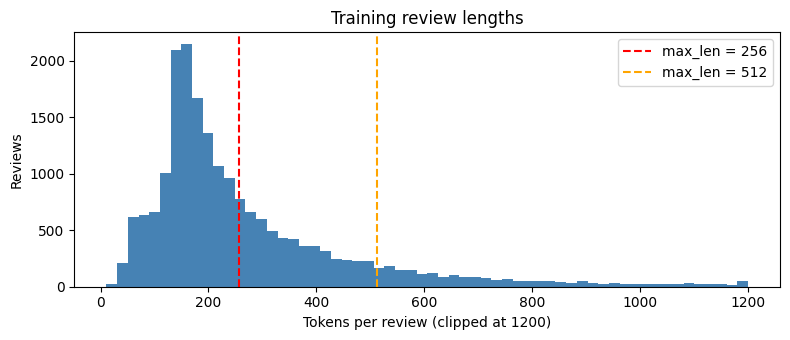

In [27]:
train_tok_lens = np.array([len(tokenize(t)) for t in train_texts])
print(f"Tokens per review: median {np.median(train_tok_lens):.0f}, mean {train_tok_lens.mean():.0f}, "
      f"90th pct {np.percentile(train_tok_lens, 90):.0f}, max {train_tok_lens.max()}")

for L in (256, 512):
    print(f"Reviews longer than {L}: {np.mean(train_tok_lens > L):.1%} | "
          f"share of all tokens discarded by truncation: {1 - np.minimum(train_tok_lens, L).sum()/train_tok_lens.sum():.1%}")

val_tokens = [tok for t in val_texts for tok in tokenize(t)]
print(f"Validation tokens mapped to <unk>: {np.mean([tok not in vocab for tok in val_tokens]):.2%}")

plt.figure(figsize=(8, 3.5))
plt.hist(np.minimum(train_tok_lens, 1200), bins=60, color="steelblue")
for L, c in [(256, "red"), (512, "orange")]:
    plt.axvline(L, color=c, linestyle="--", label=f"max_len = {L}")
plt.xlabel("Tokens per review (clipped at 1200)")
plt.ylabel("Reviews")
plt.title("Training review lengths")
plt.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/review_lengths.png", dpi=150)
plt.show()

In [28]:
_dataset_cache = {}


def get_datasets(max_len, truncation="head"):
    """Encode train/val/test once per (max_len, truncation) and cache the result."""
    key = (max_len, truncation)
    if key not in _dataset_cache:
        _dataset_cache[key] = tuple(
            IMDbDataset(texts, labels, vocab, max_len, truncation)
            for texts, labels in [(train_texts, train_labels), (val_texts, val_labels), (test_texts, test_labels)]
        )
    return _dataset_cache[key]


_tr, _, _ = get_datasets(CFG["max_len"])
print("Encoded train ids:", tuple(_tr.ids.shape), "| example (first 20 ids):", _tr.ids[0, :20].tolist())
print(f"Padding share of fixed-length batches: {1 - _tr.lengths.float().mean().item() / CFG['max_len']:.1%}")

Encoded train ids: (20000, 256) | example (first 20 ids): [871, 4649, 400, 33, 6, 653, 2045, 3, 39, 400, 221, 53, 304, 45, 6, 23, 390, 17, 332, 2832]
Padding share of fixed-length batches: 24.1%


### 4.3 Baseline (assignment configuration)

max_len 256, fixed padding, padding mask on, fp32; batch size 32, Adam lr 0.001, 10 epochs.

[baseline] parameters: 2,825,218
Epoch 1/10 - Loss: 0.3946, Accuracy: 0.8157 | Val Loss: 0.2902, Val Accuracy: 0.8788 | 13.2s <- best
Epoch 2/10 - Loss: 0.1962, Accuracy: 0.9253 | Val Loss: 0.3199, Val Accuracy: 0.8788 | 12.0s
Epoch 3/10 - Loss: 0.1014, Accuracy: 0.9646 | Val Loss: 0.4059, Val Accuracy: 0.8734 | 12.7s
Epoch 4/10 - Loss: 0.0465, Accuracy: 0.9859 | Val Loss: 0.6080, Val Accuracy: 0.8648 | 12.1s
Epoch 5/10 - Loss: 0.0309, Accuracy: 0.9899 | Val Loss: 0.7314, Val Accuracy: 0.8610 | 12.7s
Epoch 6/10 - Loss: 0.0192, Accuracy: 0.9939 | Val Loss: 0.8849, Val Accuracy: 0.8590 | 12.3s
Epoch 7/10 - Loss: 0.0213, Accuracy: 0.9930 | Val Loss: 0.9394, Val Accuracy: 0.8562 | 12.4s
Epoch 8/10 - Loss: 0.0213, Accuracy: 0.9933 | Val Loss: 1.1999, Val Accuracy: 0.8512 | 12.5s
Epoch 9/10 - Loss: 0.0228, Accuracy: 0.9921 | Val Loss: 1.1056, Val Accuracy: 0.8510 | 12.5s
Epoch 10/10 - Loss: 0.0290, Accuracy: 0.9915 | Val Loss: 1.3472, Val Accuracy: 0.8398 | 12.7s


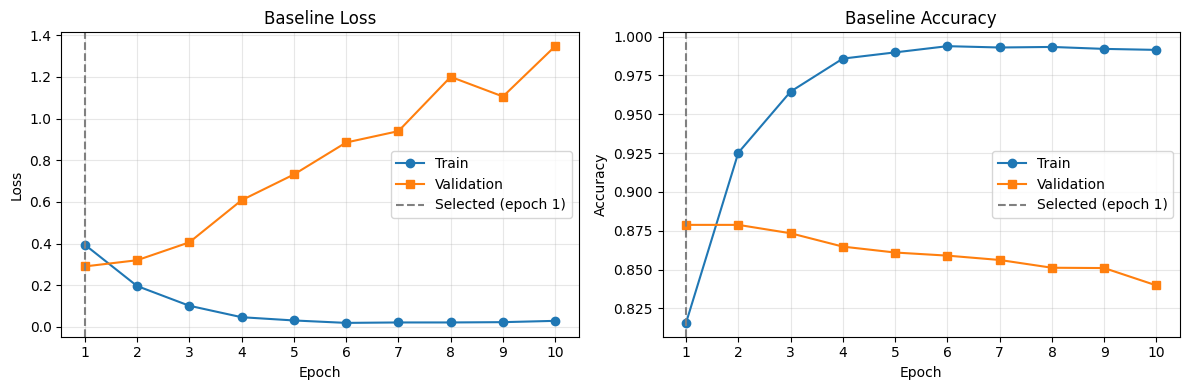

In [29]:
baseline = run_experiment("baseline", {}, get_datasets, len(vocab))
plot_history(baseline["history"], "Baseline", save_path=f"{FIG_DIR}/baseline_curves.png")

Evaluation metrics (test set, best checkpoint from epoch 1 )
Test Accuracy: 0.8669
Precision:     0.8547
Recall:        0.8840
F1-Score:      0.8691


,precision,recall,f1,support
negative (0),0.8799,0.8498,0.8646,12500.0
positive (1),0.8547,0.8840,0.8691,12500.0
macro average,0.8673,0.8669,0.8668,25000.0


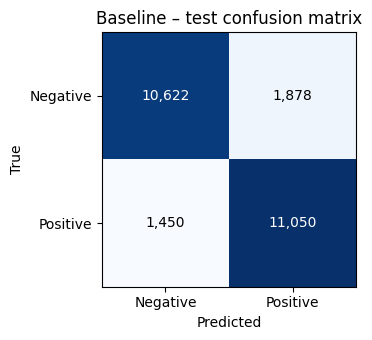

In [30]:
t = baseline["test"]
print("Evaluation metrics (test set, best checkpoint from epoch", baseline["history"]["best_epoch"], ")")
print(f"Test Accuracy: {t['accuracy']:.4f}")
print(f"Precision:     {t['precision']:.4f}")
print(f"Recall:        {t['recall']:.4f}")
print(f"F1-Score:      {t['f1']:.4f}")
display(per_class_report(t).round(4))

plot_confusion(t, "Baseline – test confusion matrix", save_path=f"{FIG_DIR}/baseline_confusion.png")

### 4.4 Challenges and solutions: training efficiency and performance experiments

Initial runs on an Apple-silicon GPU (MPS) showed three problems: (a) validation loss is lowest after epoch 1 and then rises, so the model overfits almost immediately; (b) dynamic padding barely reduced the time per epoch; (c) mixed precision was unavailable. The runs below were repeated on a Colab T4 GPU, where all experiments, including mixed precision, run. The experiments below test a solution for each challenge. Every run uses the same seed, data split, vocabulary, model size and optimiser settings as the baseline, and changes only the factors listed:

| Experiment | Change vs baseline | Challenge addressed | Hypothesis |
|---|---|---|---|
| `no_padding_mask` | Padding mask removed from attention and pooling | Performance: short reviews are mostly `<pad>`, which dilutes attention and the pooled representation | Lower accuracy; predictions depend on the amount of padding |
| `dynamic_padding` | Per-batch padding (rounded up to a multiple of 16) + length bucketing | Efficiency: fixed padding wastes computation on pad tokens (attention cost grows with L²) | Fewer positions and attention scores computed, lower time per epoch, similar accuracy |
| `dynamic_padding_amp` (CUDA only) | + fp16 mixed precision | Efficiency: fp32 matrix multiplications underuse GPU tensor cores | Further reduction in time per epoch |
| `head_tail` | Keep the first 64 and the last 192 tokens instead of the first 256 | Performance: truncation discards the end of long reviews, where the verdict often appears | Higher accuracy on long reviews at the baseline's cost |
| `maxlen512` | max_len 512 + dynamic padding (+ AMP on CUDA) | Performance: the same, by reading more of each review | Higher accuracy, at a higher cost per epoch |
| `regularised` | Dropout 0.3 and AdamW weight decay 0.1 | Performance: overfitting after the first epoch | Lower best validation loss; validation loss rises more slowly afterwards |
| `regularised_warmup_cosine` | + linear warm-up over 10% of the steps to lr 0.001, then cosine decay | Performance: large constant-lr updates late in training, no warm-up for a Post-LN Transformer | Lower validation loss in later epochs than with a constant lr |

Every run is a single seed, so §4.4.4 retrains the baseline and the two best-performing changes with two more seeds, to measure how much test accuracy varies between runs of the same configuration and whether the gains are larger than that. Time per epoch is reported as the median over the 10 epochs, which is robust to an occasional slow epoch (for example, from other programs on the machine); positions and attention scores computed per epoch measure the work independently of the hardware. Training memory (`train_mem_MB`) is the peak memory allocated to tensors during training (activations, gradients and Adam state), above what was allocated before the run.

Set `RUN_EXPERIMENTS = False` to skip this section. On a Colab T4 each run should take a few minutes.

### 4.4.1 Why dynamic padding needs rounded batch lengths (micro-benchmark)

In the first round of experiments, dynamic padding cut the padded positions but barely reduced the time per epoch on MPS, and its first epoch was the slowest of all runs. The MPS backend compiles a kernel graph for every new tensor shape; with exact batch lengths almost every batch has a new shape until all of them have been seen once. This cell times training steps of the real model for the batch lengths of 200 real bucketed batches: fixed at 256, the exact batch maxima, and the maxima rounded up to a multiple of 16. On CUDA the shape effect should be small, since CUDA does not compile per shape.

On CUDA (this run) there is no per-shape compilation cost: exact batch lengths are the fastest setting, about 25% faster per step than fixed 256-token batches, and rounding to a multiple of 16 is only 2–3% slower than exact lengths because its batches are slightly longer. Rounding was needed on MPS in the earlier run and costs little on CUDA.

In [31]:
def time_train_steps(lengths) -> tuple[float, float]:
    """Mean milliseconds per training step (real model and Adam, batch 32, random token ids) over two
    passes through `lengths`: the first pass includes any per-shape kernel compilation, as in the first
    training epoch; the second is the steady state."""
    set_seed(CFG["seed"])
    model = TransformerClassifier(len(vocab), CFG).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
    criterion = nn.CrossEntropyLoss()
    times = []
    for _ in range(2):
        sync_device()
        t0 = time.perf_counter()
        for seq_len in lengths:
            ids = torch.randint(2, len(vocab), (CFG["batch_size"], seq_len), device=DEVICE)
            labels = torch.randint(0, 2, (CFG["batch_size"],), device=DEVICE)
            optimizer.zero_grad(set_to_none=True)
            criterion(model(ids), labels).backward()
            optimizer.step()
        sync_device()
        times.append((time.perf_counter() - t0) / len(lengths) * 1000)
    return tuple(times)


# Batch lengths of 200 real bucketed training batches
_train_ds = get_datasets(CFG["max_len"])[0]
_sampler = BucketBatchSampler(_train_ds.lengths.tolist(), CFG["batch_size"], seed=CFG["seed"])
exact = [int(_train_ds.lengths[b].max()) for b in _sampler][:200]
rounded = [min(CFG["max_len"], math.ceil(L / CFG["pad_multiple"]) * CFG["pad_multiple"]) for L in exact]

# Rounded lengths are timed before exact ones, so the exact run cannot reuse their compiled shapes.
bench = {
    f"fixed ({CFG['max_len']})": ([CFG["max_len"]] * len(exact), time_train_steps([CFG["max_len"]] * len(exact))),
    f"rounded to x{CFG['pad_multiple']}": (rounded, time_train_steps(rounded)),
    "exact batch maxima": (exact, time_train_steps(exact)),
}
bench_df = pd.DataFrame(
    [dict(lengths=k, distinct_shapes=len(set(v[0])), mean_len=np.mean(v[0]),
          first_pass_ms=v[1][0], steady_state_ms=v[1][1]) for k, v in bench.items()]
).set_index("lengths")
display(bench_df.round(1))

,distinct_shapes,mean_len,first_pass_ms,steady_state_ms
lengths,,,,
fixed (256),1,256.0,20.2,20.1
rounded to x16,13,208.3,15.6,15.5
exact batch maxima,88,204.0,15.2,15.2


### 4.4.2 Experiment runs

In [32]:
RUN_EXPERIMENTS = True
USE_AMP = DEVICE.type == "cuda"     # mixed precision is CUDA-only (see Setup)

EXPERIMENTS = {
    "no_padding_mask":           dict(use_padding_mask=False),
    "dynamic_padding":           dict(dynamic_padding=True),
    "dynamic_padding_amp":       dict(dynamic_padding=True, amp=True),
    "head_tail":                 dict(truncation="head_tail"),
    "maxlen512":                 dict(max_len=512, dynamic_padding=True, amp=USE_AMP),
    "regularised":               dict(dropout=0.3, weight_decay=0.1),
    "regularised_warmup_cosine": dict(dropout=0.3, weight_decay=0.1, lr_schedule="warmup_cosine"),
}
if not USE_AMP:
    print(f"Note: AMP is CUDA-only; skipping dynamic_padding_amp on {DEVICE.type.upper()}.")
    del EXPERIMENTS["dynamic_padding_amp"]

runs = {"baseline": baseline}
if RUN_EXPERIMENTS:
    for name, overrides in EXPERIMENTS.items():
        print(f"\n===== {name}: {overrides} =====")
        runs[name] = run_experiment(name, overrides, get_datasets, len(vocab))


===== no_padding_mask: {'use_padding_mask': False} =====
[no_padding_mask] parameters: 2,825,218
Epoch 1/10 - Loss: 0.4014, Accuracy: 0.8095 | Val Loss: 0.2945, Val Accuracy: 0.8774 | 11.3s <- best
Epoch 2/10 - Loss: 0.1993, Accuracy: 0.9240 | Val Loss: 0.3201, Val Accuracy: 0.8800 | 11.7s
Epoch 3/10 - Loss: 0.1094, Accuracy: 0.9614 | Val Loss: 0.3932, Val Accuracy: 0.8728 | 11.3s
Epoch 4/10 - Loss: 0.0602, Accuracy: 0.9789 | Val Loss: 0.5538, Val Accuracy: 0.8674 | 11.4s
Epoch 5/10 - Loss: 0.0381, Accuracy: 0.9876 | Val Loss: 0.6861, Val Accuracy: 0.8622 | 11.4s
Epoch 6/10 - Loss: 0.0256, Accuracy: 0.9924 | Val Loss: 0.7473, Val Accuracy: 0.8528 | 11.4s
Epoch 7/10 - Loss: 0.0169, Accuracy: 0.9946 | Val Loss: 0.7791, Val Accuracy: 0.8542 | 11.4s
Epoch 8/10 - Loss: 0.0174, Accuracy: 0.9938 | Val Loss: 0.9714, Val Accuracy: 0.8448 | 11.3s
Epoch 9/10 - Loss: 0.0200, Accuracy: 0.9941 | Val Loss: 1.1224, Val Accuracy: 0.8466 | 11.3s
Epoch 10/10 - Loss: 0.0156, Accuracy: 0.9952 | Val Loss: 

In [33]:
summary = pd.DataFrame([r["row"] for r in runs.values()]).set_index("experiment")
base = summary.loc["baseline"]
summary["speedup_vs_baseline"] = base["median_epoch_s"] / summary["median_epoch_s"]
summary["attn_work_vs_baseline"] = summary["attn_entries_per_epoch_M"] / base["attn_entries_per_epoch_M"]
summary.to_csv("experiment_summary.csv")
pd.options.display.float_format = "{:.4f}".format

CONFIG_COLS = ["seed", "max_len", "truncation", "padding_mask", "dynamic_padding", "amp",
               "dropout", "weight_decay", "lr_schedule"]
display(summary[CONFIG_COLS])
display(summary.drop(columns=CONFIG_COLS))

,seed,max_len,truncation,padding_mask,dynamic_padding,amp,dropout,weight_decay,lr_schedule
experiment,,,,,,,,,
baseline,42,256,head,True,False,False,0.1000,0.0000,constant
no_padding_mask,42,256,head,False,False,False,0.1000,0.0000,constant
dynamic_padding,42,256,head,True,True,False,0.1000,0.0000,constant
dynamic_padding_amp,42,256,head,True,True,True,0.1000,0.0000,constant
head_tail,42,256,head_tail,True,False,False,0.1000,0.0000,constant
maxlen512,42,512,head,True,True,True,0.1000,0.0000,constant
regularised,42,256,head,True,False,False,0.3000,0.1000,constant
regularised_warmup_cosine,42,256,head,True,False,False,0.3000,0.1000,warmup_cosine


,best_epoch,val_loss,val_acc,final_val_loss,final_val_acc,test_acc,test_precision,test_recall,test_f1,median_epoch_s,total_train_s,positions_per_epoch_M,attn_entries_per_epoch_M,train_mem_MB,speedup_vs_baseline,attn_work_vs_baseline
experiment,,,,,,,,,,,,,,,,
baseline,1,0.2902,0.8788,1.3472,0.8398,0.8669,0.8547,0.8840,0.8691,12.5241,125.1577,5.1200,1310.7200,288.5234,1.0000,1.0000
no_padding_mask,1,0.2945,0.8774,1.1859,0.8530,0.8598,0.8307,0.9038,0.8657,11.3554,113.9898,5.1200,1310.7200,271.2339,1.1029,1.0000
dynamic_padding,1,0.2999,0.8756,1.1188,0.8454,0.8570,0.8210,0.9132,0.8646,9.8243,98.3212,4.0247,875.5339,271.2734,1.2748,0.6680
dynamic_padding_amp,1,0.3013,0.8790,1.2823,0.8542,0.8580,0.8210,0.9157,0.8658,8.0736,80.9786,4.0247,875.5339,207.8926,1.5512,0.6680
head_tail,1,0.2665,0.8888,0.9043,0.8626,0.8805,0.8565,0.9142,0.8844,12.6263,126.1425,5.1200,1310.7200,271.2734,0.9919,1.0000
maxlen512,1,0.2759,0.8842,0.9974,0.8594,0.8706,0.8368,0.9208,0.8768,11.6146,116.2175,5.1714,1701.1065,617.4785,1.0783,1.2978
regularised,1,0.2904,0.8752,0.8059,0.8518,0.8639,0.8628,0.8655,0.8641,12.6558,126.5784,5.1200,1310.7200,271.9766,0.9896,1.0000
regularised_warmup_cosine,2,0.3379,0.8666,0.9724,0.8608,0.8326,0.9211,0.7276,0.8130,12.6572,126.6123,5.1200,1310.7200,271.7422,0.9895,1.0000


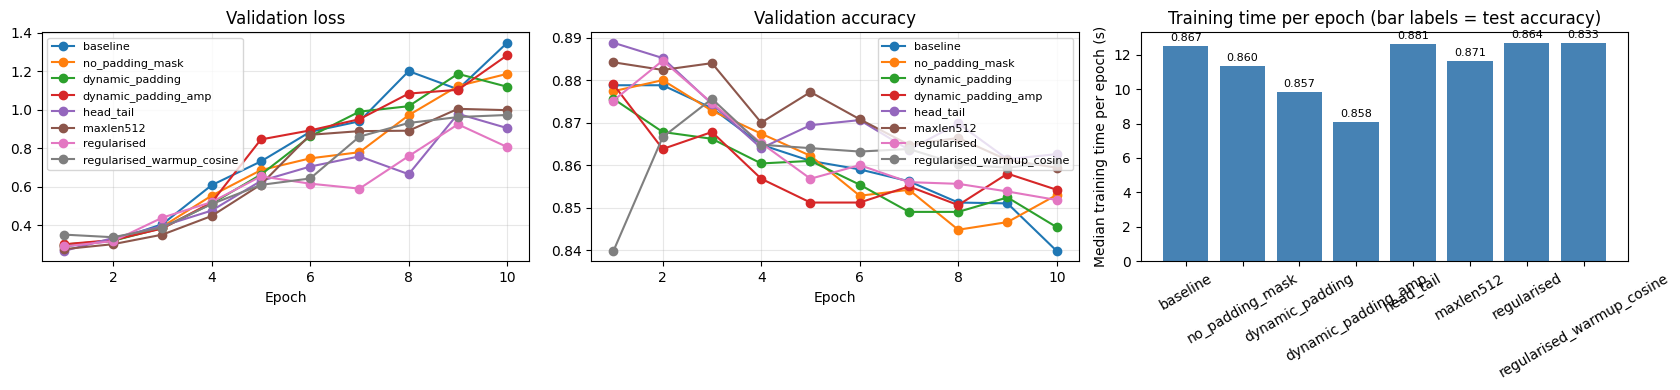

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for name, r in runs.items():
    h = r["history"]
    ep = range(1, len(h["val_loss"]) + 1)
    axes[0].plot(ep, h["val_loss"], "o-", label=name)
    axes[1].plot(ep, h["val_acc"], "o-", label=name)
axes[0].set_title("Validation loss"); axes[1].set_title("Validation accuracy")
for ax in axes[:2]:
    ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=8)

names = list(summary.index)
bars = axes[2].bar(names, summary["median_epoch_s"], color="steelblue")
axes[2].bar_label(bars, labels=[f"{a:.3f}" for a in summary["test_acc"]], padding=2, fontsize=8)
axes[2].set_ylabel("Median training time per epoch (s)")
axes[2].set_title("Training time per epoch (bar labels = test accuracy)")
axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/experiments_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

### 4.4.3 Overfitting: baseline vs regularised training

Train and validation curves of the baseline and the two regularised runs. The gap between the train and validation curves, and how quickly validation loss rises after its minimum, show how much each change reduces overfitting.

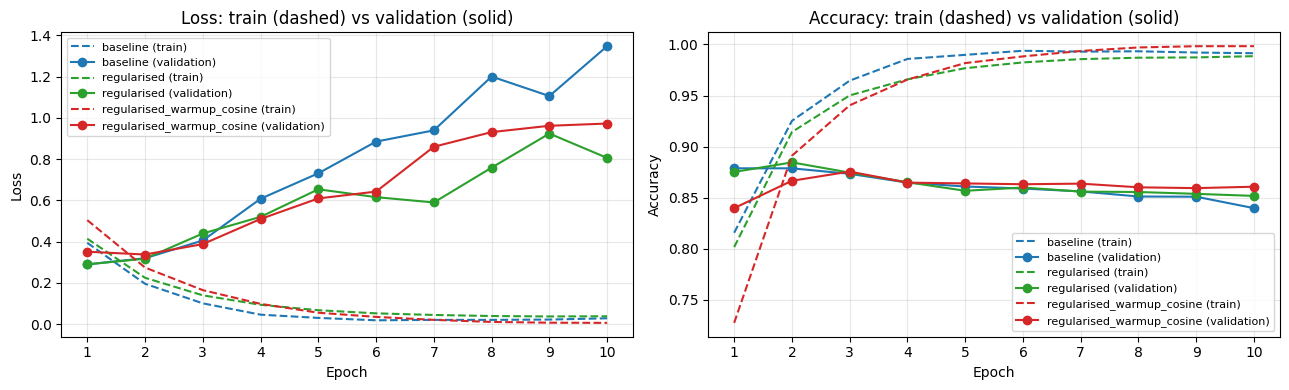

In [35]:
reg_names = [n for n in ["baseline", "regularised", "regularised_warmup_cosine"] if n in runs]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, color in zip(reg_names, ["tab:blue", "tab:green", "tab:red"]):
    h = runs[name]["history"]
    ep = list(range(1, len(h["val_loss"]) + 1))
    for ax, key in [(axes[0], "loss"), (axes[1], "acc")]:
        ax.plot(ep, h[f"train_{key}"], "--", color=color, label=f"{name} (train)")
        ax.plot(ep, h[f"val_{key}"], "o-", color=color, label=f"{name} (validation)")
for ax, label in [(axes[0], "Loss"), (axes[1], "Accuracy")]:
    ax.set_title(f"{label}: train (dashed) vs validation (solid)")
    ax.set_xlabel("Epoch"); ax.set_ylabel(label); ax.set_xticks(ep); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/overfitting_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

### 4.4.4 Run-to-run variation (seed repeats)

Each comparison above is a single run. To judge which differences are real, the baseline and the two changes with the lowest validation loss (`head_tail` and `maxlen512`, §4.4.5) are retrained with two more seeds. The seed changes the weight initialisation, dropout and batch order; the data split and vocabulary stay fixed. Differences smaller than the variation between seeds should not be read as effects. With 3 seeds per configuration, Welch's t-test is only a rough guide.

In [36]:
from scipy import stats

RUN_SEED_REPEATS = True
SEEDS = [42, 1, 2]                                      # 42 = the runs above
SEED_CONFIGS = ["baseline", "head_tail", "maxlen512"]    # the baseline and the two best changes

seed_rows = []
for config in [c for c in SEED_CONFIGS if c in runs]:
    seed_rows.append({**runs[config]["row"], "config": config})
    if RUN_SEED_REPEATS:
        for seed in SEEDS[1:]:
            print(f"\n===== {config}, seed {seed} =====")
            overrides = {**EXPERIMENTS.get(config, {}), "seed": seed}
            row = run_experiment(f"{config}_seed{seed}", overrides, get_datasets, len(vocab))["row"]
            seed_rows.append({**row, "config": config})

seed_df = pd.DataFrame(seed_rows).set_index("experiment")[
    ["config", "seed", "best_epoch", "val_loss", "val_acc", "test_acc", "test_f1", "median_epoch_s"]]
display(seed_df)
seed_summary = seed_df.groupby("config", sort=False)[["val_loss", "test_acc", "test_f1"]].agg(["mean", "std"])
display(seed_summary)

base_acc = seed_df.loc[seed_df["config"] == "baseline", "test_acc"]
for config in [c for c in seed_summary.index if c != "baseline"]:
    acc = seed_df.loc[seed_df["config"] == config, "test_acc"]
    t_stat, p_value = stats.ttest_ind(acc, base_acc, equal_var=False)
    print(f"{config}: test accuracy {acc.mean() - base_acc.mean():+.4f} vs baseline "
          f"(mean over {len(acc)} vs {len(base_acc)} seeds; Welch t = {t_stat:.2f}, p = {p_value:.3f})")


===== baseline, seed 1 =====
[baseline_seed1] parameters: 2,825,218
Epoch 1/10 - Loss: 0.3925, Accuracy: 0.8124 | Val Loss: 0.2837, Val Accuracy: 0.8804 | 12.7s <- best
Epoch 2/10 - Loss: 0.1967, Accuracy: 0.9238 | Val Loss: 0.3455, Val Accuracy: 0.8612 | 12.7s
Epoch 3/10 - Loss: 0.1023, Accuracy: 0.9631 | Val Loss: 0.4796, Val Accuracy: 0.8520 | 12.7s
Epoch 4/10 - Loss: 0.0504, Accuracy: 0.9838 | Val Loss: 0.6235, Val Accuracy: 0.8598 | 12.7s
Epoch 5/10 - Loss: 0.0334, Accuracy: 0.9885 | Val Loss: 0.8024, Val Accuracy: 0.8566 | 12.6s
Epoch 6/10 - Loss: 0.0237, Accuracy: 0.9921 | Val Loss: 0.9366, Val Accuracy: 0.8554 | 12.7s
Epoch 7/10 - Loss: 0.0185, Accuracy: 0.9939 | Val Loss: 1.0556, Val Accuracy: 0.8522 | 12.7s
Epoch 8/10 - Loss: 0.0182, Accuracy: 0.9933 | Val Loss: 1.0238, Val Accuracy: 0.8420 | 12.7s
Epoch 9/10 - Loss: 0.0225, Accuracy: 0.9925 | Val Loss: 1.1880, Val Accuracy: 0.8436 | 12.7s
Epoch 10/10 - Loss: 0.0290, Accuracy: 0.9900 | Val Loss: 1.1186, Val Accuracy: 0.8444 

,config,seed,best_epoch,val_loss,val_acc,test_acc,test_f1,median_epoch_s
experiment,,,,,,,,
baseline,baseline,42,1,0.2902,0.8788,0.8669,0.8691,12.5241
baseline_seed1,baseline,1,1,0.2837,0.8804,0.8664,0.8638,12.6593
baseline_seed2,baseline,2,1,0.3077,0.8692,0.8464,0.8313,12.6559
head_tail,head_tail,42,1,0.2665,0.8888,0.8805,0.8844,12.6263
head_tail_seed1,head_tail,1,1,0.2660,0.8914,0.8789,0.8754,12.6530
head_tail_seed2,head_tail,2,1,0.2686,0.8894,0.8734,0.8669,12.6602
maxlen512,maxlen512,42,1,0.2759,0.8842,0.8706,0.8768,11.6146
maxlen512_seed1,maxlen512,1,2,0.2696,0.8938,0.8754,0.8744,11.5731
maxlen512_seed2,maxlen512,2,1,0.2591,0.8924,0.8773,0.8747,11.5587


val_loss        test_acc        test_f1       
              mean    std     mean    std    mean    std
config                                                  
baseline    0.2939 0.0124   0.8599 0.0117  0.8547 0.0205
head_tail   0.2670 0.0014   0.8776 0.0038  0.8756 0.0088
maxlen512   0.2682 0.0085   0.8744 0.0035  0.8753 0.0013

head_tail: test accuracy +0.0177 vs baseline (mean over 3 vs 3 seeds; Welch t = 2.50, p = 0.109)
maxlen512: test accuracy +0.0145 vs baseline (mean over 3 vs 3 seeds; Welch t = 2.07, p = 0.155)


### 4.4.5 Final model selection

The baseline (§4.3) is the model trained with the assignment's exact configuration. Across all experiments, the final model is chosen with the same rule used for checkpoints: the lowest validation loss. The test set is not used to choose; test metrics of all runs are shown for comparison only. Compare the gap in validation loss between the top candidates with the seed variation of validation loss in §4.4.4 to judge whether the choice is clear. The cell also plots the selected model's training and validation curves and its test confusion matrix.

Selected model: head_tail (epoch 1: validation loss 0.2665, validation accuracy 0.8888)
Test: accuracy 0.8805, precision 0.8565, recall 0.9142, F1 0.8844 | TN 10,585 FP 1,915 FN 1,072 TP 11,428
Median training time per epoch: 12.6 s (baseline 12.5 s)


,best_epoch,val_loss,val_acc,test_acc,test_f1,median_epoch_s
experiment,,,,,,
head_tail,1,0.2665,0.8888,0.8805,0.8844,12.6263
maxlen512,1,0.2759,0.8842,0.8706,0.8768,11.6146
baseline,1,0.2902,0.8788,0.8669,0.8691,12.5241
regularised,1,0.2904,0.8752,0.8639,0.8641,12.6558
no_padding_mask,1,0.2945,0.8774,0.8598,0.8657,11.3554
dynamic_padding,1,0.2999,0.8756,0.8570,0.8646,9.8243
dynamic_padding_amp,1,0.3013,0.8790,0.8580,0.8658,8.0736
regularised_warmup_cosine,2,0.3379,0.8666,0.8326,0.8130,12.6572


,precision,recall,f1,support
negative (0),0.9080,0.8468,0.8764,12500.0000
positive (1),0.8565,0.9142,0.8844,12500.0000
macro average,0.8823,0.8805,0.8804,25000.0000


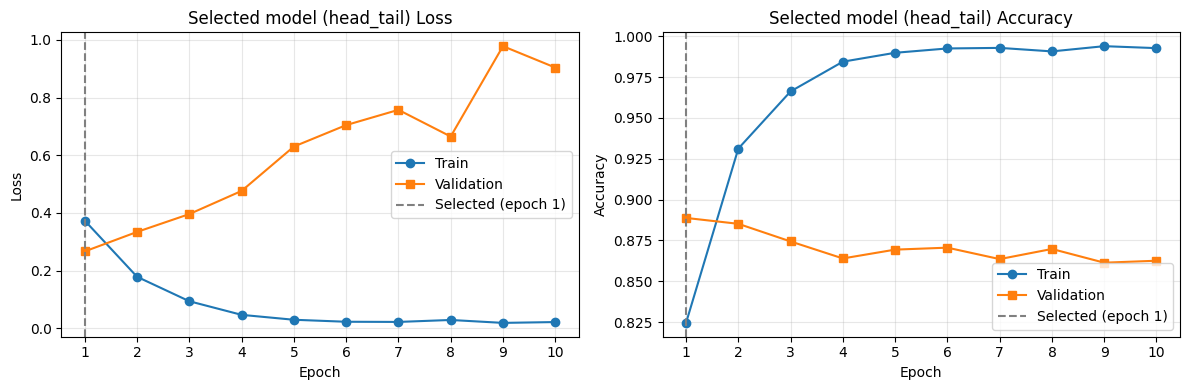

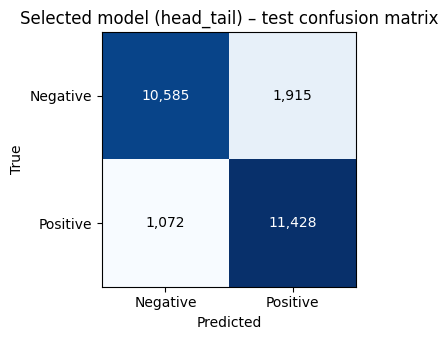

In [37]:
# Lowest best-epoch validation loss across the experiments (the seed repeats duplicate the baseline and are
# not candidates). The test set plays no part in the choice; it is only reported for the chosen model.
final_name = summary["val_loss"].idxmin()
final = summary.loc[final_name]
ft = runs[final_name]["test"]
print(f"Selected model: {final_name} (epoch {final['best_epoch']}: validation loss {final['val_loss']:.4f}, "
      f"validation accuracy {final['val_acc']:.4f})")
print(f"Test: accuracy {ft['accuracy']:.4f}, precision {ft['precision']:.4f}, recall {ft['recall']:.4f}, "
      f"F1 {ft['f1']:.4f} | TN {ft['tn']:,} FP {ft['fp']:,} FN {ft['fn']:,} TP {ft['tp']:,}")
print(f"Median training time per epoch: {final['median_epoch_s']:.1f} s "
      f"(baseline {summary.loc['baseline', 'median_epoch_s']:.1f} s)")
display(summary.sort_values("val_loss")[["best_epoch", "val_loss", "val_acc", "test_acc", "test_f1", "median_epoch_s"]])
display(per_class_report(ft).round(4))
plot_history(runs[final_name]["history"], f"Selected model ({final_name})", save_path=f"{FIG_DIR}/selected_model_curves.png")
plot_confusion(ft, f"Selected model ({final_name}) – test confusion matrix",
               save_path=f"{FIG_DIR}/selected_model_confusion.png")

### 4.5 Error analysis and attention inspection (baseline model)

Misclassified test reviews: 3,328 of 25,000

Most confident mistakes:
- true=neg, P(positive)=0.994, tokens=68
   This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is really well done (which is not often the case for this type of movies) and you can see that Chuck (in one of his first role)is a great actor. The final fight with the sherif deputy in the bullring is a masterpiece! ...

- true=neg, P(positive)=0.991, tokens=87
   This film has the language, the style and the attitude down ... plus greats rides from Occy (a world champ) and the great Jerry Lopez. John Philbin as Turtle has the surf pidgin down, and the surfing scenes are still the best ever. A true classic that can be seen many times. Nia Peeples is a babe, and Laird Hamilton shows the early stuff that has made him the world's number one extreme surfer. ...

- true=neg, P(positive)=0.989, tokens=60
   Well, I must say, I initially found this short to be quite average, but having wat

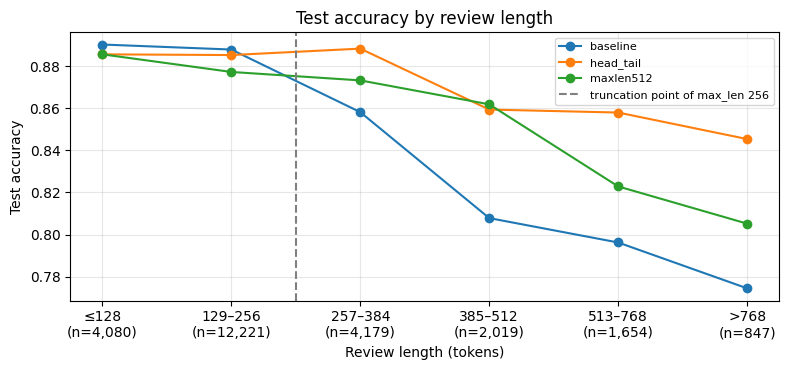

In [38]:
t = baseline["test"]
wrong = np.where(t["y_pred"] != t["y_true"])[0]
confidence = np.abs(t["prob_pos"][wrong] - 0.5)
print(f"Misclassified test reviews: {len(wrong):,} of {len(t['y_true']):,}\n")
print("Most confident mistakes:")
for i in wrong[np.argsort(-confidence)][:3]:
    print(f"- true={'pos' if t['y_true'][i] else 'neg'}, P(positive)={t['prob_pos'][i]:.3f}, "
          f"tokens={len(tokenize(test_texts[i]))}")
    print("  ", _HTML_TAG_RE.sub(" ", test_texts[i])[:500].replace("\n", " "), "...\n")

# Is the model worse on reviews that were truncated? Compare the models that read long reviews differently.
test_lens = np.array([len(tokenize(x)) for x in test_texts])
long_review = test_lens > CFG["max_len"]
print(f"Test reviews longer than {CFG['max_len']} tokens: {long_review.sum():,} of {len(test_lens):,}")
length_models = [n for n in ["baseline", "head_tail", "maxlen512"] if n in runs]
for name in length_models:
    correct = runs[name]["test"]["y_pred"] == runs[name]["test"]["y_true"]
    print(f"{name:<10} accuracy: <= {CFG['max_len']} tokens {correct[~long_review].mean():.4f} | "
          f"> {CFG['max_len']} tokens {correct[long_review].mean():.4f}")

# Accuracy by review length: where in the length distribution do the errors occur?
edges = [128, 256, 384, 512, 768]                              # bin upper edges (tokens)
bin_names = ["≤128", "129–256", "257–384", "385–512", "513–768", ">768"]
bin_idx = np.digitize(test_lens, edges, right=True)            # 0 .. len(bin_names) - 1
tick_labels = [f"{b}\n(n={np.sum(bin_idx == k):,})" for k, b in enumerate(bin_names)]
fig, ax = plt.subplots(figsize=(8, 3.8))
for name in length_models:
    correct = runs[name]["test"]["y_pred"] == runs[name]["test"]["y_true"]
    ax.plot(tick_labels, [correct[bin_idx == k].mean() for k in range(len(bin_names))], "o-", label=name)
ax.axvline(1.5, color="grey", linestyle="--", label=f"truncation point of max_len {CFG['max_len']}")
ax.set_xlabel("Review length (tokens)"); ax.set_ylabel("Test accuracy")
ax.set_title("Test accuracy by review length"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/accuracy_by_length.png", dpi=150); plt.show()

Review (label=neg, P(positive)=0.014):
i found this movie really hard to sit through , my attention kept wandering off the tv . as far as romantic movies go . . this one is the worst i ' ve seen . don ' t bother with it .


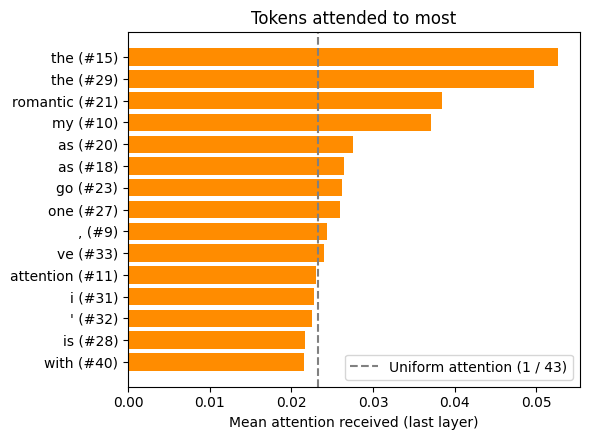

In [39]:
model = baseline["model"].eval()
idx = next(i for i, x in enumerate(test_texts) if 30 <= len(tokenize(x)) <= 60)
ids, length = encode(test_texts[idx], vocab, CFG["max_len"])

last_attn = model.layers[-1].attn
last_attn.store_attn = True
with torch.no_grad():
    p = torch.softmax(model(torch.tensor([ids], device=DEVICE)), dim=-1)[0, 1].item()
last_attn.store_attn = False

# Attention each token RECEIVES in the last layer: average over heads and over real query positions
received = last_attn.last_attn[0].mean(0)[:length, :length].mean(0).cpu().numpy()
tokens = [itos[i] for i in ids[:length]]
top = np.argsort(-received)[:15][::-1]

print(f"Review (label={'pos' if test_labels[idx] else 'neg'}, P(positive)={p:.3f}):")
print(" ".join(tokens))
plt.figure(figsize=(6, 4.5))
plt.barh([f"{tokens[i]} (#{i})" for i in top], received[top], color="darkorange")
plt.axvline(1 / length, color="grey", linestyle="--", label=f"Uniform attention (1 / {length})")
plt.legend(loc="lower right")
plt.xlabel("Mean attention received (last layer)"); plt.title("Tokens attended to most")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/attention_example.png", dpi=150); plt.show()

### 4.5.1 Decision threshold

A review is classified as positive when P(positive) ≥ 0.5. If the model's probabilities lean towards one class (for example, recall well above precision), a different threshold can balance the errors. This cell picks the threshold that maximises validation accuracy and applies it, unchanged, to the test set, so the test set still plays no part in the choice.

In [40]:
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
rows = []
for name in dict.fromkeys(["baseline", final_name]):          # dict.fromkeys: unique, in order
    r = runs[name]
    val_loader = make_loaders(get_datasets(r["cfg"]["max_len"], r["cfg"]["truncation"]), r["cfg"])[1]
    val_out = evaluate(r["model"], val_loader, nn.CrossEntropyLoss(), return_preds=True)
    val_acc = [np.mean((val_out["prob_pos"] >= th) == val_out["y_true"]) for th in thresholds]
    best_th = thresholds[int(np.argmax(val_acc))]
    test_out = r["test"]
    for label, th in [("0.50 (default)", 0.5), (f"{best_th:.2f} (tuned on validation)", best_th)]:
        m = binary_metrics(test_out["y_true"], (test_out["prob_pos"] >= th).astype(int))
        rows.append(dict(model=name, threshold=label, **{k: m[k] for k in ["accuracy", "precision", "recall", "f1", "fp", "fn"]}))
display(pd.DataFrame(rows).set_index(["model", "threshold"]))

accuracy  precision  recall     f1  \
model     threshold                                                        
baseline  0.50 (default)                0.8669     0.8547  0.8840 0.8691   
          0.55 (tuned on validation)    0.8660     0.8696  0.8613 0.8654   
head_tail 0.50 (default)                0.8805     0.8565  0.9142 0.8844   
          0.60 (tuned on validation)    0.8818     0.8833  0.8800 0.8816   

                                        fp    fn  
model     threshold                               
baseline  0.50 (default)              1878  1450  
          0.55 (tuned on validation)  1615  1734  
head_tail 0.50 (default)              1915  1072  
          0.60 (tuned on validation)  1454  1500

In [41]:
# Numbers for the report: the headline values quoted in §5 and in the PDF report, in one place.
b = runs["baseline"]
bh, bt = b["history"], b["test"]
print(f"Vocabulary: {len(vocab):,} | parameters: {count_parameters(b['model']):,}")
print(f"Baseline: best epoch {bh['best_epoch']} (val loss {min(bh['val_loss']):.4f}, val acc {bh['val_acc'][bh['best_epoch'] - 1]:.4f}); "
      f"epoch {CFG['epochs']}: val loss {bh['val_loss'][-1]:.4f}, val acc {bh['val_acc'][-1]:.4f}")
print(f"Baseline test: acc {bt['accuracy']:.4f}, precision {bt['precision']:.4f}, recall {bt['recall']:.4f}, F1 {bt['f1']:.4f} | "
      f"TN {bt['tn']:,} FP {bt['fp']:,} FN {bt['fn']:,} TP {bt['tp']:,}")
_tr = get_datasets(CFG["max_len"])[0]
print(f"Padding share of fixed-length batches: {1 - _tr.lengths.float().mean().item() / CFG['max_len']:.1%} | "
      f"training reviews > {CFG['max_len']} tokens: {np.mean(train_tok_lens > CFG['max_len']):.1%}")
if "seed_summary" in globals():
    for config, r in seed_summary.iterrows():
        print(f"Seeds ({config}): val loss {r[('val_loss', 'mean')]:.4f} ± {r[('val_loss', 'std')]:.4f}, "
              f"test acc {r[('test_acc', 'mean')]:.4f} ± {r[('test_acc', 'std')]:.4f}")
print(f"Selected model: {final_name}")
cols = ["best_epoch", "val_loss", "final_val_loss", "final_val_acc", "test_acc", "test_f1",
        "median_epoch_s", "speedup_vs_baseline", "attn_work_vs_baseline", "train_mem_MB"]
display(summary[cols])

Vocabulary: 20,000 | parameters: 2,825,218
Baseline: best epoch 1 (val loss 0.2902, val acc 0.8788); epoch 10: val loss 1.3472, val acc 0.8398
Baseline test: acc 0.8669, precision 0.8547, recall 0.8840, F1 0.8691 | TN 10,622 FP 1,878 FN 1,450 TP 11,050
Padding share of fixed-length batches: 24.1% | training reviews > 256 tokens: 36.2%
Seeds (baseline): val loss 0.2939 ± 0.0124, test acc 0.8599 ± 0.0117
Seeds (head_tail): val loss 0.2670 ± 0.0014, test acc 0.8776 ± 0.0038
Seeds (maxlen512): val loss 0.2682 ± 0.0085, test acc 0.8744 ± 0.0035
Selected model: head_tail


,best_epoch,val_loss,final_val_loss,final_val_acc,test_acc,test_f1,median_epoch_s,speedup_vs_baseline,attn_work_vs_baseline,train_mem_MB
experiment,,,,,,,,,,
baseline,1,0.2902,1.3472,0.8398,0.8669,0.8691,12.5241,1.0000,1.0000,288.5234
no_padding_mask,1,0.2945,1.1859,0.8530,0.8598,0.8657,11.3554,1.1029,1.0000,271.2339
dynamic_padding,1,0.2999,1.1188,0.8454,0.8570,0.8646,9.8243,1.2748,0.6680,271.2734
dynamic_padding_amp,1,0.3013,1.2823,0.8542,0.8580,0.8658,8.0736,1.5512,0.6680,207.8926
head_tail,1,0.2665,0.9043,0.8626,0.8805,0.8844,12.6263,0.9919,1.0000,271.2734
maxlen512,1,0.2759,0.9974,0.8594,0.8706,0.8768,11.6146,1.0783,1.2978,617.4785
regularised,1,0.2904,0.8059,0.8518,0.8639,0.8641,12.6558,0.9896,1.0000,271.9766
regularised_warmup_cosine,2,0.3379,0.9724,0.8608,0.8326,0.8130,12.6572,0.9895,1.0000,271.7422


## 5. Results summary

The analysis of these results, the challenges and solutions, and the answers to the two questions are in the report, `assignment-3_wimukthi_a1988198.pdf` (Sections 5–7). This section summarises the implementation and the headline numbers printed above.

### 5.1 Implementation summary
- **Data:** IMDb from Hugging Face `datasets`; official train split shuffled (seed 42) and split 80/20 into 20,000 training and 5,000 validation reviews; the 25,000-review test set is used only for final evaluation. HTML tags removed, text lowercased and tokenised with `basic_english` rules; vocabulary of 20,000 tokens built from the training split only (min frequency 2); sequences truncated/padded to 256. Data checks (§4.1.1): 66 duplicate copies in the training split, 28 reviews shared between train and validation, 93 between train and test.
- **Model:** token embedding (d_model = 128, scaled by √d_model) + sinusoidal positional encoding → 2 Post-LN encoder blocks (4-head self-attention, FFN 128→256→128 with ReLU, residual connections, LayerNorm, dropout 0.1) → masked mean pooling → linear layer to 2 logits → softmax. 2,825,218 parameters, 2,560,000 of them in the embedding table.
- **Training:** Adam (lr 0.001), batch size 32, 10 epochs, cross-entropy over the two softmax outputs (equivalent to binary cross-entropy), gradient clipping at norm 1.0.
- **Model selection:** within each run, the checkpoint with the lowest validation loss (baseline: epoch 1); across experiments, the run with the lowest validation loss (head + tail truncation, §4.4.5). The test set did not influence any choice.

### 5.2 Test-set results
| Metric (test set, 25,000 reviews) | Baseline (assignment configuration) | Selected model (head + tail) |
|---|---|---|
| Accuracy | 0.8669 | 0.8805 |
| Precision | 0.8547 | 0.8565 |
| Recall | 0.8840 | 0.9142 |
| F1-score | 0.8691 | 0.8844 |

Over three seeds (§4.4.4), test accuracy is 0.8599 ± 0.0117 for the baseline, 0.8776 ± 0.0038 for head + tail truncation and 0.8744 ± 0.0035 for max_len 512. All six runs of the two truncation fixes beat all three baseline runs, but with three seeds the differences are not statistically significant (Welch p = 0.109 and 0.155). Training ran on a Google Colab Tesla T4 (PyTorch 2.11, CUDA).
